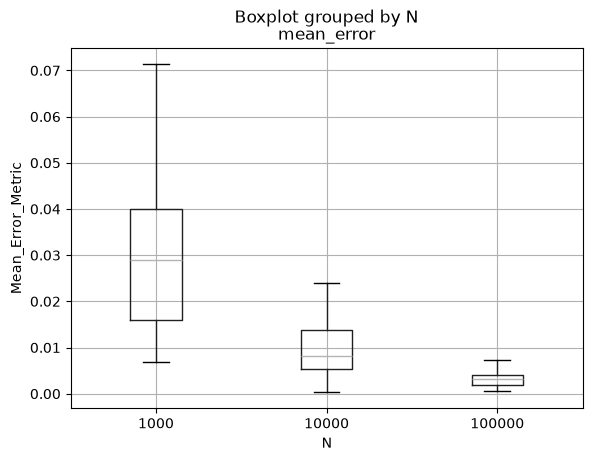

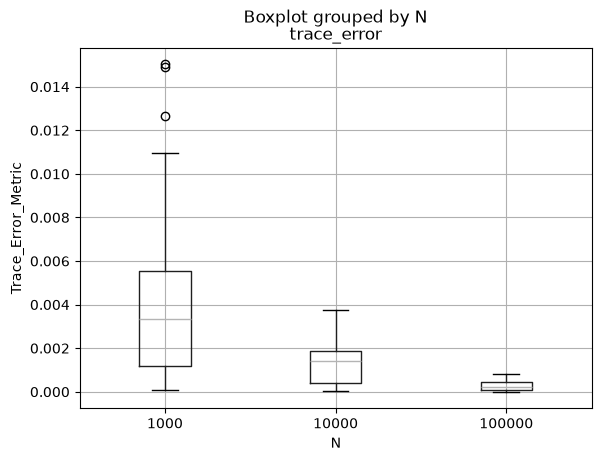

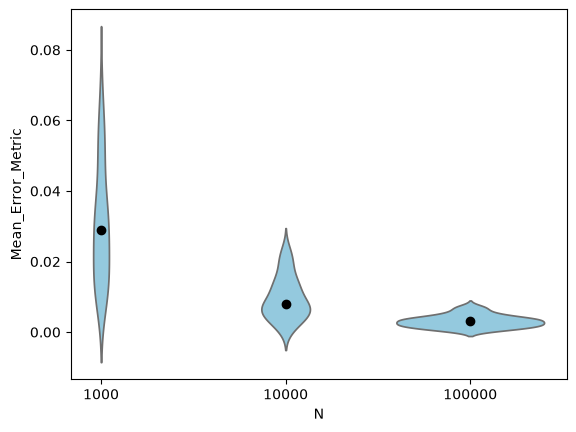

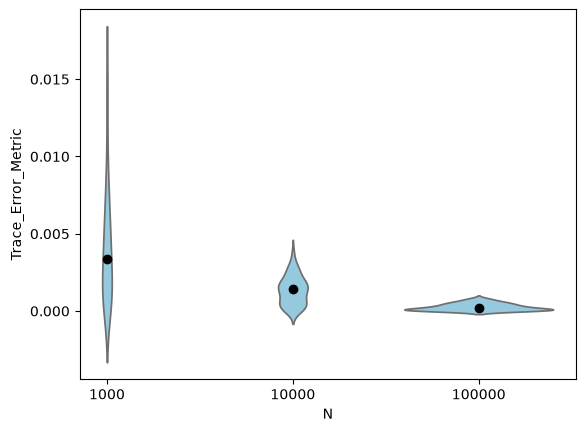

In [9]:
# #EMCEE SAMPLING WITH DIFFERENCE DATA SETS

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

from EMCEE_MCMC_DIFF_DATASETS import *

ndim = 2
nwalkers = 4

prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.0],
          [0.0, 0.1]]) #prior covariance vector

A = np.array([[2,3],[-1,2]])
dim = 2

noise_cov = 0.1 * np.identity(2)

all_results = {}
rows1 = []

mcmc = EMCEE_MCMC_DIFF_DATASETS(prior_mean, prior_cov,ndim, nwalkers,noise_cov)

for nsteps in [250, 2500, 25000]:
    chains, mean_errors, trace_errors = mcmc.run_all(A, nsteps=nsteps,burn_in=50, base_seed = 123, Nrep = 50)

    all_results[nsteps] = {
        "chains": chains,
        "mean_errors": mean_errors,
        "trace_errors": trace_errors
    }

    for rep_idx, (mean_err, trace_err) in enumerate(zip(mean_errors, trace_errors)):
        rows1.append({
            "nsteps": nsteps,
            "replicate": rep_idx,
            "mean_error": float(mean_err),
            "trace_error": float(trace_err)
        })

df1 = pd.DataFrame(rows1)
df1["N"] = df1["nsteps"] * nwalkers

 
df1.boxplot(column="mean_error", by="N")
plt.ylabel('Mean_Error_Metric')
plt.show()


df1.boxplot(column="trace_error", by="N")
plt.ylabel('Trace_Error_Metric')
plt.show()

sns.violinplot(data = df1, x = "N", y="mean_error", color = "skyblue", inner = None)
plt.ylabel('Mean_Error_Metric')

medians_mean = df1.groupby("N")["mean_error"].median()

for i, median in enumerate(medians_mean):
    plt.scatter(i, median, color="black", zorder=10)

plt.show()



sns.violinplot(data = df1,x="N", y="trace_error", color = "skyblue", inner = None)
plt.ylabel('Trace_Error_Metric')

medians_trace = df1.groupby("N")["trace_error"].median()

for i, median in enumerate(medians_trace):
    plt.scatter(i, median, color="black", zorder=10)

plt.show()





parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [ 0.2327894  -0.25848097]
data shape: (2,)
A shape: (2, 2)
prior_mean shape: (2,)
prior_cov shape: (2, 2)
parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [-0.29010266 -1.04566759]
data shape: (2,)
A shape: (2, 2)
prior_mean shape: (2,)
prior_cov shape: (2, 2)
parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [-3.42258894 -1.45322972]
data shape: (2,)
A shape: (2, 2)
prior_mean shape: (2,)
prior_cov shape: (2, 2)
parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [ 1.68598023 -0.06800293]
data shape: (2,)
A shape: (2, 2)
prior_mean shape: (2,)
prior_cov shape: (2, 2)
parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [-1.81223529 -1.20207441]
data shape: (2,)
A shape: (2, 2)
prior_mean shape: (2,)
prior_cov shape: (2, 2)
parameter_sample shape: (2,)
noise_sample shape: (2,)
data shape: (2,)
data: [-0.7704

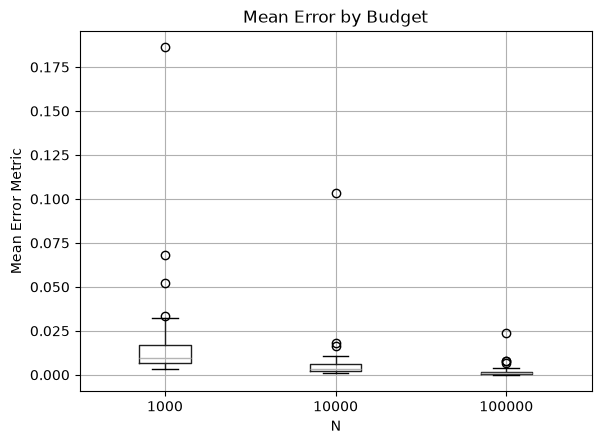

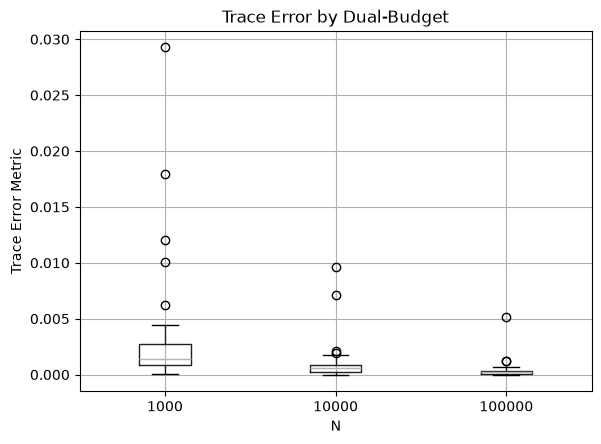

In [10]:
import numpy as np
from Dual_Problem_Bayes_Class_DIFF_DATASETS import *
from BayesianMVLinGaussIP import BayesianMVLinGaussIP


prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.0],
          [0.0, 0.1]]) #prior covariance vector

A = np.array([[2,3],[-1,2]])
dim = 2

noise_cov = 0.1 * np.identity(2)
sigma_val = 1

dual_problem = Dual_Problem_Bayes_Class_DIFF_DATASETS(prior_mean=prior_mean, prior_cov=prior_cov,ndim = dim, noise_cov=noise_cov)


budgets = [1000, 10000, 100000]
mean_errors_dual = []
trace_errors_dual = []


all_results = {}
base_seed = 123

for budget in budgets:
    


    psi = dual_problem.psi_kl
    post_means = []
    post_covs = []
    replicate_errors = []
    replicate_trace = []

    prior_samples = dual_problem.sample_from_prior(
            N=budget, Nrep=50, base_seed=123
        )

    for rep in range(prior_samples.shape[0]):
        data_seed = base_seed + rep
        data_rng = np.random.default_rng(data_seed)

        data, true_parameter = dual_problem.generate_data(
            A=A,
            prior_mean=dual_problem.prior_mean,
            prior_cov=dual_problem.prior_cov,
            noise_cov=dual_problem.noise_cov,
            rng=data_rng
        )

        model = BayesianMVLinGaussIP(prior_mean=prior_mean, prior_cov = prior_cov, dim = 2, noise_cov=noise_cov) 
                    # TNP: True posterior for comparison to computed one.
        print("data:", data)
        print("data shape:", np.shape(data))
        print("A shape:", A.shape)
        print("prior_mean shape:", np.shape(prior_mean))
        print("prior_cov shape:", np.shape(prior_cov))
        
        exact_posterior_cov, exact_posterior_mean  = model.posterior_calculations(
                                A=A,
                                y=data
                            )

    


        theta_rep = prior_samples[rep]

        g_theta_rep = dual_problem.vectorized_log_likelihood(
            data=data,
            theta_vals=theta_rep,
            A=A,
            noise_cov=noise_cov
        )

        result = dual_problem.solve_saa_jax(g_theta_rep, sigma_val, psi)

        semi_vals = dual_problem.semianalytic_vectorized(
            theta=theta_rep,
            data=data,
            A=A,
            noise_cov=noise_cov,
            result=result,
            sigma_val=sigma_val,
            psi=psi
        )

        post_mean_rep = np.mean(theta_rep * semi_vals[:, None], axis=0)
        mean_error_rep = np.linalg.norm(post_mean_rep - exact_posterior_mean)
        centered = theta_rep - post_mean_rep
        post_cov_rep = np.mean(centered[:,:, None] * centered[:,None,:] * semi_vals[:,None,None],axis = 0)
        trace_actual = np.trace(exact_posterior_cov)
        trace_dual = np.trace(post_cov_rep)
        trace_error_rep = abs(trace_dual-trace_actual)

        post_means.append(post_mean_rep)
        post_covs.append(post_cov_rep)
        replicate_errors.append(mean_error_rep)
        replicate_trace.append(trace_error_rep)

    all_results[budget] = {
        "prior_samples": prior_samples,
        "post_means": post_means,
        "mean_errors": replicate_errors,
        "trace_errors": replicate_trace
    }

    for budget, results in all_results.items():
        print(f"budget = {budget}")
        print(f"  number of replicates = {len(results['prior_samples'])}")
        for i, theta_rep in enumerate(results["prior_samples"]):
            print(f"  replicate {i}: shape = {theta_rep.shape}")
        print(f"  mean errors = {results['mean_errors']}")
        print(f"  trace errors = {results['trace_errors']}")

import pandas as pd
import numpy as np
rows3 = []

for budget, results in all_results.items():
    for rep_idx,(mean_err, trace_err) in enumerate(zip(results["mean_errors"],results["trace_errors"])):
        rows3.append({
            "budget": budget,
            "replicate": rep_idx,
            "mean_error": float(mean_err),
            "trace_error": float(trace_err)
        })

df3 = pd.DataFrame(rows3)

#print(df)

df3["N"] = df3["budget"]



df3.boxplot(column="mean_error", by="N")
plt.ylabel("Mean Error Metric")
plt.title("Mean Error by Budget")
plt.suptitle("")  # removes the automatic subtitle
plt.show()

df3.boxplot(column="trace_error", by="N")
plt.ylabel("Trace Error Metric")
plt.title("Trace Error by Dual-Budget")
plt.suptitle("")  # removes the automatic subtitle
plt.show()

(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-40.7953591, dtype=float64), Array([383340442, 642469539], dtype=uint32))
step 0, loss: 82.24972948355475
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-80.42730186, dtype=float64), Array([ 739853491, 1055571153], dtype=uint32))
step 0, loss: 108.56621845837748
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-103.0072475, dtype=float64), Array([3719380766, 3418183213], dtype=uint32))
step 0, loss: 204.37112567906482
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-90.09863696, dtype=float64), Array([622031414,  47082471], dtype=uint32))
step 0, loss: 190.96838386264977
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-125.36004096, dtype=float64), Array([2079203305, 2428291487], dtype=uint32))
step 0, loss: 163.52854248408505
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-139.76094353, dtype=float64), Array([1868194018,  344923936], dtype=uint32))
step 0, loss: 177.13295589439974
(2, 2)
[[0.1 0. ]
 [0.  0.1]]
(Array(-110.92716698, dtype=float64), Array([ 873234011, 40746

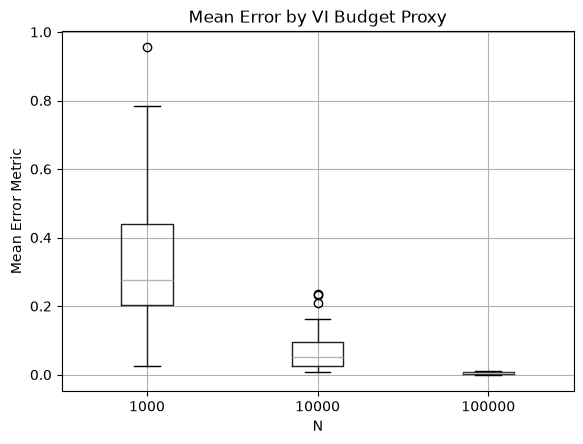

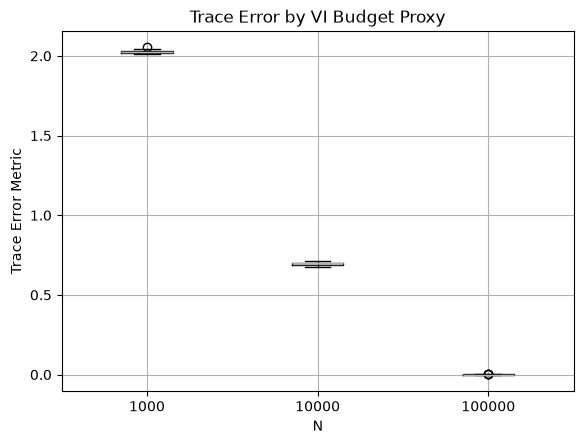

In [11]:
## Replicate Sampling VI Test
import jax
import jax.numpy as jnp
from FullRankMVNVI_DIFF_DATASETS import *
from BayesianMVLinGaussIP import BayesianMVLinGaussIP
import numpy as np
import pandas as pd
import optax
import matplotlib.pyplot as plt

prior_mean = np.array([0.4,0]) #Prior mean vector
prior_cov = np.array([[0.1, 0.],
                      [0., 0.1]])

print(np.shape(prior_cov))
print(prior_cov)

A = np.array([[2,3],[-1,2]],dtype=float)
dim = 2

noise_cov = 0.1 * np.identity(2)

prior_cov_inv = jnp.linalg.inv(prior_cov)
noise_cov_inv = jnp.linalg.inv(noise_cov)

VI = FullRankVI_DIFF_DATASETS(dim, prior_mean=prior_mean, prior_cov=prior_cov, noise_cov = noise_cov) #The class is here



all_results = {}
rows2 = []
num_data_replicates = 50
base_seed = 123

for n_steps in [100, 1000, 10000]:
    optimizer = optax.adam(learning_rate=1e-3)

    replicate_mean_errors_VI = []
    replicate_trace_errors_VI = []
    replicate_params = []

    for rep in range(num_data_replicates):
        data_seed = base_seed + rep
        init_seed = base_seed + 1000 + rep

        data_rng = np.random.default_rng(data_seed)
        key = jax.random.PRNGKey(init_seed)
    
        data, true_parameter = VI.generate_data(
                A=A,
                prior_mean=VI.prior_mean,
                prior_cov=VI.prior_cov,
                noise_cov=VI.noise_cov,
                rng=data_rng
            )
    
        model = BayesianMVLinGaussIP(prior_mean=prior_mean, prior_cov = prior_cov, dim = 2, noise_cov=noise_cov) 
                        # TNP: True posterior for comparison to computed one.

            
        exact_posterior_cov, exact_posterior_mean  = model.posterior_calculations(
                                    A=A,
                                    y=data
                                )

        params = VI.init_params() #params are mu and raw_L

        elbo_initial = VI.elbo(
        key,
        params,
        A,
        data,
        prior_mean,
        prior_cov_inv,
        noise_cov_inv,
        n_samples=10
        )
        print(elbo_initial)

        rep_results = VI.fit(
        key=key,
        params=params,
        optimizer=optimizer,
        A=A,
        y=data,
        prior_mean=prior_mean,
        prior_cov_inv=prior_cov_inv,
        noise_cov_inv=noise_cov_inv,
        n_steps=n_steps,
        )


    
        
        optimized_params = rep_results[0]
        optimized_mu = optimized_params["mu"]
        L = VI.make_L(optimized_params["raw_L"]) 
        optimized_covariance = L @ L.T
        trace_VI = np.trace(optimized_covariance)
        trace_actual = np.trace(exact_posterior_cov)
        

        mean_error_VI = np.linalg.norm(optimized_mu - exact_posterior_mean)
        trace_error_VI = abs(trace_VI-trace_actual)


        replicate_mean_errors_VI.append(mean_error_VI)
        replicate_trace_errors_VI.append(trace_error_VI)
        replicate_params.append(optimized_params)


        rows2.append({
            "nsteps": n_steps,
            "replicate": rep,
            "mean_error": float(mean_error_VI),
            "trace_error": float(trace_error_VI)
        })

    all_results[n_steps] = {
        "optimized_params": replicate_params,
        "mean_errors": replicate_mean_errors_VI,
        "trace_errors": replicate_trace_errors_VI
    }

    # Optional: ELBO for the last replicate only
    elbo_optimized = VI.elbo(
        key,
        replicate_params[-1],
        A,
        data,
        prior_mean,
        prior_cov_inv,
        noise_cov_inv,
        n_samples=10
    )
    print(elbo_optimized)

for nsteps, results in all_results.items():
    print(f"nsteps = {nsteps}")
    print(f"  number of replicates = {len(results['optimized_params'])}")
    for i, rep_params in enumerate(results["optimized_params"]):
        print(f"  replicate {i}: mu shape = {rep_params['mu'].shape}")
    print(f"  mean errors = {results['mean_errors']}")
    print(f" trace errors = {results['trace_errors']}")

import matplotlib.pyplot as plt

df2 = pd.DataFrame(rows2)

n_samples = 10

print(df2)

df2["N"] = df2["nsteps"] * n_samples   # if you want to use the same proxy idea
df2.boxplot(column="mean_error", by="N")
plt.ylabel("Mean Error Metric")
plt.title("Mean Error by VI Budget Proxy")
plt.suptitle("")
plt.show()

df2.boxplot(column="trace_error", by="N")
plt.ylabel("Trace Error Metric")
plt.title("Trace Error by VI Budget Proxy")
plt.suptitle("")
plt.show()

     nsteps  replicate  mean_error  trace_error       N method    budget
0     100.0          0    0.138817     2.017968    1000     VI       NaN
1     100.0          1    0.252708     2.034994    1000     VI       NaN
2     100.0          2    0.955268     2.021341    1000     VI       NaN
3     100.0          3    0.170244     2.031524    1000     VI       NaN
4     100.0          4    0.561751     2.031534    1000     VI       NaN
..      ...        ...         ...          ...     ...    ...       ...
445     NaN         45    0.000801     0.000152  100000   Dual  100000.0
446     NaN         46    0.000126     0.000363  100000   Dual  100000.0
447     NaN         47    0.006582     0.001254  100000   Dual  100000.0
448     NaN         48    0.000388     0.000057  100000   Dual  100000.0
449     NaN         49    0.001584     0.000008  100000   Dual  100000.0

[450 rows x 7 columns]


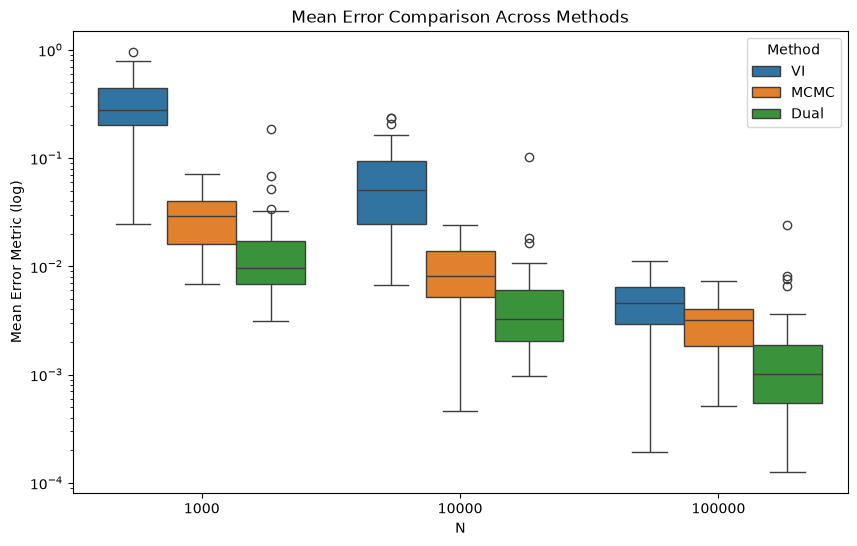

In [12]:
# Plot for all
df1["method"] = "MCMC"
df2["method"] = "VI"
df3["method"] = "Dual"

df_all = pd.concat([df2, df1, df3], ignore_index=True)
print(df_all)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_all,
    x="N",
    y="mean_error",
    hue="method"
)

plt.yscale('log') 
plt.ylabel("Mean Error Metric (log)")
plt.xlabel("N")
plt.title("Mean Error Comparison Across Methods")
plt.legend(title="Method")
plt.savefig('MeanErrorPlot.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()


     nsteps  replicate  mean_error  trace_error       N method    budget
0     100.0          0    0.138817     2.017968    1000     VI       NaN
1     100.0          1    0.252708     2.034994    1000     VI       NaN
2     100.0          2    0.955268     2.021341    1000     VI       NaN
3     100.0          3    0.170244     2.031524    1000     VI       NaN
4     100.0          4    0.561751     2.031534    1000     VI       NaN
..      ...        ...         ...          ...     ...    ...       ...
445     NaN         45    0.000801     0.000152  100000   Dual  100000.0
446     NaN         46    0.000126     0.000363  100000   Dual  100000.0
447     NaN         47    0.006582     0.001254  100000   Dual  100000.0
448     NaN         48    0.000388     0.000057  100000   Dual  100000.0
449     NaN         49    0.001584     0.000008  100000   Dual  100000.0

[450 rows x 7 columns]


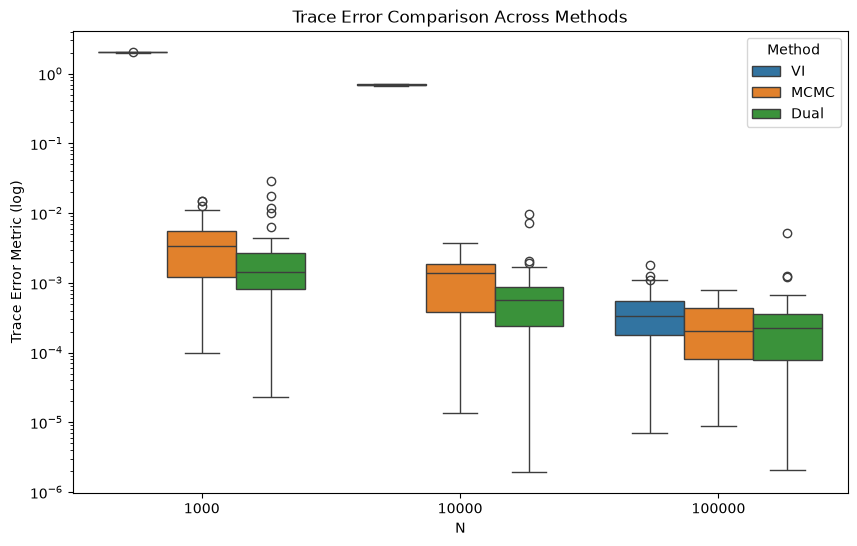

In [13]:
# Plot for all
df1["method"] = "MCMC"
df2["method"] = "VI"
df3["method"] = "Dual"

df_all = pd.concat([df2, df1, df3], ignore_index=True)
print(df_all)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_all,
    x="N",
    y="trace_error",
    hue="method"
)

plt.yscale('log')
plt.ylabel("Trace Error Metric (log)")
plt.xlabel("N")
plt.title("Trace Error Comparison Across Methods")
plt.legend(title="Method")
plt.savefig('TraceErrorPlot.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

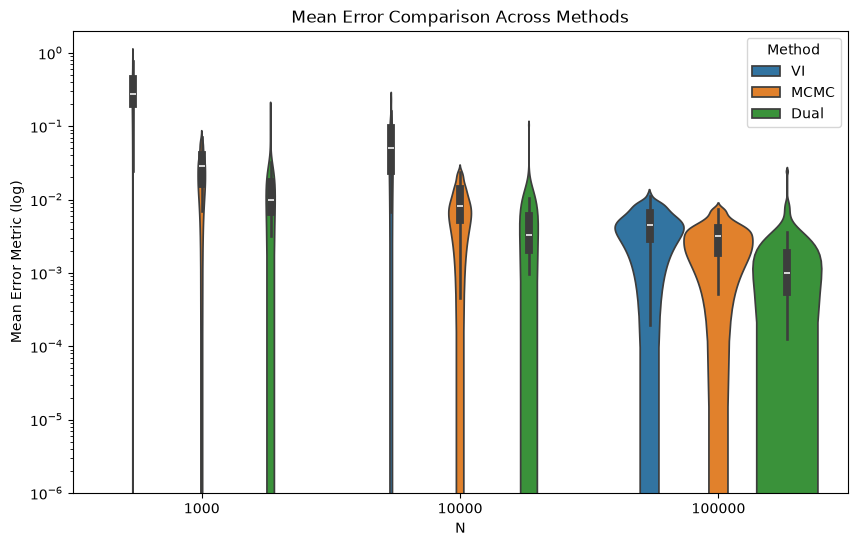

In [16]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_all,
    x="N",
    y="mean_error",
    hue="method"
)

plt.yscale("log")
plt.ylim(bottom=1e-6)

plt.ylabel("Mean Error Metric (log)")
plt.xlabel("N")
plt.title("Mean Error Comparison Across Methods")
plt.legend(title="Method")
plt.savefig(
    "MeanErrorViolinPlot.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight"
)
plt.show()